<a href="https://colab.research.google.com/github/juancferreyrar/customers-like-you-pca-svd-ferreyra/blob/main/Ferreyra_retail_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Retail Analysis Project

## Section 1: Data Processing

Importing Relevant Libraries

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, scipy.sparse as sp, time
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize

Mounted at /content/drive


Loading Yearly Information

In [11]:
file_path = "/content/drive/MyDrive/data/raw/online_retail_II.xlsx"
sheets = pd.read_excel(file_path, sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)

print(df.columns.tolist(), len(df))

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country'] 1067371


DE1: Data Inspection

In [13]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)
display(df.head())

df.info()

(1067371, 8)
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


Checking number of Rows and Missing data

In [14]:
for name, sheet in sheets.items():
    print(name, len(sheet))
df.isnull().sum()

Year 2009-2010 525461
Year 2010-2011 541910


,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


We can see how both "Description" and "Customer ID" have a large part of missing data, and we also see how for the two years in total, we have the expected number of rows as 1,067,371

ML1 Method Choice

I opted on choosing a Truncated SVD over PCA as our customer-product matrix is going to be sparse, having most values being zero. As SVD can work with the sparse matrices without needing to center the data, it is an option I prefer over PCA. We can further use SVD for the customer and product factors that will be accounted for in the reccommendation section of the project.

DE2: Data Cleaning

Removing cancellations

In [16]:
clean_df = df.copy()
cleaning_log = {}
cancelled = clean_df['Invoice'].astype(str).str.startswith("C")
cleaning_log['Cancelled Invoices'] = cancelled.sum()
clean_df = clean_df[~cancelled].copy()
cleaning_log

{'Cancelled Invoices': np.int64(19494)}

With this step, we have removed 19,494 rows representing the cancelled invoice rows

We now remove any non-positive quantitites and prices

In [17]:
invalid = (clean_df['Quantity']<= 0)|(clean_df['Price']<= 0)
cleaning_log['Non-positive quantity or price'] = invalid.sum()
clean_df = clean_df[~invalid].copy()
cleaning_log

{'Cancelled Invoices': np.int64(19494),
 'Non-positive quantity or price': np.int64(6207)}

We have now removed 6,207 rows from the dataset, representing the non-positive quantities

We now remove the non-product stock codes

In [18]:
non_products = ['POST', 'M', 'D', 'BANK CHARGES']
invalid_codes = clean_df['StockCode'].isin(non_products)
cleaning_log['Non-product codes'] = invalid_codes.sum()
clean_df = clean_df[~invalid_codes].copy()
cleaning_log

{'Cancelled Invoices': np.int64(19494),
 'Non-positive quantity or price': np.int64(6207),
 'Non-product codes': np.int64(2802)}

This removes an additional 2,802 rows

We ensure that all the codes that need to be removed are deleted, but making sure that not all the codes that include a letter are as these are still valid

In [21]:
codes = clean_df['StockCode'].astype(str)
codes[codes.str.contains('[A-Za-z]')].value_counts()

,count
StockCode,
85123A,5686
85099B,4124
82494L,2063
85099C,1926
85099F,1885
...,...
84387A,1
84857B,1
B,1


In [22]:
codes[codes.str.fullmatch('[A-Za-z ]+')].value_counts()

,count
StockCode,
DOT,1436
ADJUST,36
DCGSSGIRL,23
DCGSSBOY,21
PADS,17
m,5
AMAZONFEE,4
S,3
B,1


After noticing a code that was just "B", we filter out the non-numbered codes, and proceeed to remove them, but first we understand the meaning of each code

In [23]:
clean_df[clean_df['StockCode'].isin(['m', 'S', 'B'])][['StockCode', 'Description']].drop_duplicates()

,StockCode,Description
96608,m,Manual
181508,S,SAMPLES
825443,B,Adjust bad debt


Now that we verify that these are in fact non-product, we can remove them

In [24]:
non_products = ['DOT', 'ADJUST', 'AMAZONFEE', 'm', 'S', 'B']
invalid_codes = clean_df['StockCode'].isin(non_products)
cleaning_log['Additional non-product codes'] = invalid_codes.sum()
clean_df = clean_df[~invalid_codes].copy()
cleaning_log

{'Cancelled Invoices': np.int64(19494),
 'Non-positive quantity or price': np.int64(6207),
 'Non-product codes': np.int64(2802),
 'Additional non-product codes': np.int64(1485)}

We now have 1,485 rows removed in this specific check

We now remove all the missing customer IDs

In [25]:
missing_customers = clean_df['Customer ID'].isnull()
cleaning_log['Missing Customer ID'] = missing_customers.sum()
clean_df = clean_df[~missing_customers].copy()
cleaning_log

{'Cancelled Invoices': np.int64(19494),
 'Non-positive quantity or price': np.int64(6207),
 'Non-product codes': np.int64(2802),
 'Additional non-product codes': np.int64(1485),
 'Missing Customer ID': np.int64(234466)}

We have now removed 234,466 rows of unnecessary data in this section

We now see how many rows we have removed in total

In [26]:
pd.Series(cleaning_log)
print("Original rows:", len(df))
print("Remaining rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

Original rows: 1067371
Remaining rows: 802917
Rows removed: 264454


## Prototype Truncated SVD

ML2: Prototype

In [29]:
np.random.seed(2)
A_test = sp.random(10, 8, density=0.3, format='csr', random_state=2)
print(A_test.toarray())

[[0.54269608 0.77224477 0.         0.28093451 0.06355835 0.
  0.         0.19871568]
 [0.         0.         0.         0.80219698 0.         0.
  0.62329813 0.        ]
 [0.         0.81546143 0.14092422 0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.72900717 0.         0.
  0.         0.86310343]
 [0.00552212 0.         0.         0.         0.         0.
  0.32518332 0.        ]
 [0.72960618 0.         0.         0.07404465 0.11586906 0.33089802
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.        ]
 [0.         0.         0.         0.         0.63755747 0.
  0.77127035 0.        ]
 [0.         0.07455064 0.98688694 0.         0.         0.
  0.35846573 0.        ]
 [0.31098232 0.         0.         0.         0.70685734 0.
  0.         0.        ]]


Now that we understand our matrix has 10 rows, 8 columns, and mostly zeroes, we can fit the Truncated SVD

In [30]:
svd = TruncatedSVD(n_components=3, random_state=2)
svd.fit(A_test)
print(svd.explained_variance_ratio_)
print(svd.explained_variance_ratio_.sum())

[0.10197618 0.26086178 0.2299326 ]
0.5927705617156822


Now the products have been reduced to 3 components, retaining around 59% of the variance

DE3: Splitting data by time

We first verify the date range

In [31]:
clean_df['InvoiceDate'].min(), clean_df['InvoiceDate'].max()

(Timestamp('2009-12-01 07:45:00'), Timestamp('2011-12-09 12:50:00'))

We split for testing

In [32]:
cutoff = pd.Timestamp('2011-10-09')
train = clean_df[clean_df['InvoiceDate'] < cutoff].copy()
test = clean_df[clean_df['InvoiceDate'] >= cutoff].copy()
len(train), len(test)

(683919, 118998)

DE3: Identifying New-Product Purchases

In [33]:
bought_before = train[['Customer ID', 'StockCode']].drop_duplicates()
bought_before.head()

,Customer ID,StockCode
0,13085.0,85048
1,13085.0,79323P
2,13085.0,79323W
3,13085.0,22041
4,13085.0,21232


Now we verify that customers did not purchase the same product during testing and training

In [34]:
test = test.merge(bought_before, on=['Customer ID', 'StockCode'],
                  how='left', indicator=True)

new_purchases = test[test['_merge'] == 'left_only'].copy()

len(new_purchases)

73251

Now we check if these customers and products exist in the training data

In [35]:
new_purchases = new_purchases[
    new_purchases['Customer ID'].isin(train['Customer ID']) &
    new_purchases['StockCode'].isin(train['StockCode'])
]
len(new_purchases)

52899

These 52,899 transactions are eligible for customers and products that exist in the training data

In [36]:
new_purchases[['Customer ID', 'StockCode']].drop_duplicates().shape

(45979, 2)

Now we have 45,979 unique customer-product pairs to analyze for the reccomendation

In [37]:
new_purchases['Customer ID'].nunique()

1917

We have 1917 eligible customers were we can evaluate on held-out purchases with hit rate at 10

We save the files to avoid losing the data

In [39]:
train.to_csv("/content/drive/MyDrive/Customers_Like_You/data /raw /online_retail_II.xlsx", index=False)

new_purchases[['Customer ID', 'StockCode']].drop_duplicates().to_csv(
    "/content/drive/MyDrive/Customers_Like_You/data /raw /online_retail_II.xlsx",
    index=False)

DE 4: Customer Product Matrix

We create the sparse customer x product matrix with training data

In [40]:
cust = {c: i for i, c in enumerate(train['Customer ID'].unique())}
prod = {p: j for j, p in enumerate(train['StockCode'].unique())}
rows = train['Customer ID'].map(cust)
cols = train['StockCode'].map(prod)
len(cust), len(prod)

(5473, 4535)

These represent the dimensions in the customer-product matrix, with the number of unique customers and the number of unique products being represented, respectively

In [41]:
vals = np.log1p(train['Quantity'])

A = sp.csr_matrix((vals, (rows, cols)),
                  shape=(len(cust), len(prod)))

A.shape, A.nnz

((5473, 4535), 417548)

Finally, we save the data

In [43]:
sp.save_npz("/content/drive/MyDrive/Customers_Like_You/data /raw /online_retail_II.xlsx", A)
pd.DataFrame(cust.items(), columns=['Customer ID', 'Row']).to_csv(
    "/content/drive/MyDrive/Customers_Like_You/data /raw /online_retail_II.xlsx", index=False)

pd.DataFrame(prod.items(), columns=['StockCode', 'Column']).to_csv(
    "/content/drive/MyDrive/Customers_Like_You/data /raw /online_retail_II.xlsx", index=False)

ML2: Fit Truncated SVD

We now test using the different values of k

In [44]:
k_values = [10, 20, 50, 100, 200]
errors = []
for k in k_values:
    svd = TruncatedSVD(n_components=k, random_state=2)
    A_reduced = svd.fit_transform(A)
    A_reconstructed = A_reduced @ svd.components_
    error = np.linalg.norm(A.toarray() - A_reconstructed) / np.linalg.norm(A.toarray())
    errors.append(error)
print(errors)

[np.float64(0.7561385974882318), np.float64(0.6873528678227735), np.float64(0.584484746572338), np.float64(0.49609086131122354), np.float64(0.39917181634210286)]


As the number of SVD components increase, the reconstruction error decreases, which means we are preserving more of the original customer-product information

We can plot the reconstruction error to better understand the data

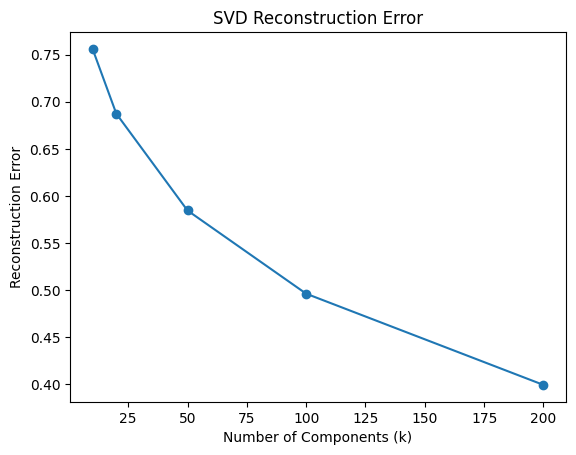

In [46]:
import matplotlib.pyplot as plt
plt.plot(k_values, errors, marker='o')
plt.xlabel('Number of Components (k)')
plt.ylabel('Reconstruction Error')
plt.title('SVD Reconstruction Error')
plt.show()

As we can see from the graph, the closest shift is near k = 100, so we can choose it provisionally until doing further checks, which gives a reconstruction error of around 50%

DE 5: Matrix Statistics

We gather relevant information such as matrix dimensions, number of nonzero entries, sparsity percentage, and memory usage

In [47]:
print("Matrix shape:", A.shape)
print("Nonzero entries:", A.nnz)
print("Sparsity:", (1 - A.nnz / (A.shape[0] * A.shape[1])) * 100, "%")
dense_mb = A.shape[0] * A.shape[1] * 8 / 1024**2
sparse_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1024**2
print("Dense memory (MB):", dense_mb)
print("Sparse memory (MB):", sparse_mb)

Matrix shape: (5473, 4535)
Nonzero entries: 417548
Sparsity: 98.31769913483271 %
Dense memory (MB): 189.36199188232422
Sparse memory (MB): 4.799339294433594


We see the 5,473 customers and 4,535 products, with 417,548 non-zero entries. We also see how sparsity is 89.32%, as customers only buy a small fraction of the products. If we kept every entry, we would need around 189.36mb of memory, with the sparse memory beng 4.80mb

ML3: Product Recommendations

We use the previously mentioned k = 100

In [48]:
svd = TruncatedSVD(n_components=100, random_state=2).fit(A)
P_vec = normalize(svd.components_.T)

In [50]:
def similar(j, n=10):
    s = P_vec @ P_vec[j]
    s[j] = -np.inf
    return np.argsort(-s)[:n]
similar(0)

array([3072, 3423, 4417,  880, 4269, 2521, 3713, 1182, 3232, 1710])

Now we can see the customer recommendations

In [52]:
def recommend(i, n=10):
    bought = A[i].indices
    scores = P_vec[bought].sum(axis=0) @ P_vec.T
    scores[bought] = -np.inf
    return np.argsort(-scores)[:n]
recommend(0)

array([1586, 1552, 1073, 2783, 1266,  921,  373, 2847, 2369,  504])

ML4: Product Recommendations Evaluation

In [56]:
test_customers = new_purchases['Customer ID'].unique()
test_rows = [cust[c] for c in test_customers]
len(test_rows)
product_codes = list(prod.keys())
hits = 0
for c in test_customers:
    actual = set(new_purchases[new_purchases['Customer ID'] == c]['StockCode'])
    predicted = set(product_codes[i] for i in recommend(cust[c]))
    if actual & predicted:
        hits += 1
hit_rate = hits / len(test_customers)
hit_rate

0.20657276995305165

The SVD recommendation model achieved a Hit Rate at 10 of 20.66%, which means around 1 in 5 test customers had at least one future purchase appear in our models top-10 recommendations

Now we compare the model to the best-seller baseline

In [57]:
best_sellers = train.groupby('StockCode')['Quantity'].sum().sort_values(ascending=False)
best_sellers.head(10)

,Quantity
StockCode,
84077,95977
21212,87086
85123A,86539
85099B,85687
23166,76902
84879,71390
17003,67734
22197,59195
21977,53123


In [58]:
baseline_hits = 0
for c in test_customers:
    actual = set(new_purchases[new_purchases['Customer ID'] == c]['StockCode'])
    bought = set(train[train['Customer ID'] == c]['StockCode'])
    predicted = set(best_sellers.index.difference(bought, sort=False)[:10])
    if actual & predicted:
        baseline_hits += 1
baseline_rate = baseline_hits / len(test_customers)
baseline_rate

0.17475221700573812

As we can see, the output shows a baseline hit rate at 10 percentage of 17.4%, meaning it is underperforming when compared to the SVD model

Now we time the nighlty recommendation job

In [59]:
start = time.time()
for i in range(A.shape[0]):
    recommend(i)
runtime = time.time() - start
runtime

4.562572479248047

Our taget goal was of less than 60 seconds, and our actual results show around 4.56 seconds (Note, this time does not include the loading of the data or the fitting of the SVD)

ML5: Comparing PCA vs Truncated SVD

We will continue to use k = 100 for PCA for consistency

In [63]:
start = time.time()
pca = PCA(n_components=100, svd_solver="arpack", random_state=2).fit(A)
pca_time = time.time() - start
pca_time

2.0064189434051514

The model takes around 2.01 seconds to fit

In [64]:
pca.explained_variance_ratio_.sum()

np.float64(0.7482591216087021)

For the variance, we can see that with k = 100, around 74.83% of the total variance is explained

In order to compare, we evaluate the SVD fit time

In [65]:
start = time.time()
svd = TruncatedSVD(n_components=100, random_state=2).fit(A)
svd_time = time.time() - start
svd_time

1.7206265926361084

We see that the time is around .30 seconds lower than PCA

In [66]:
svd.explained_variance_ratio_.sum()

np.float64(0.7476731106807283)

We also see that with SVD, the model explains around 74.77% of the variance, slightly below PCA

We now consider the storage size usage for PCA

In [67]:
pca_scores = pca.transform(A)
svd_scores = svd.transform(A)

pca_mb = (pca_scores.nbytes + pca.components_.nbytes) / 1024**2
svd_mb = (svd_scores.nbytes + svd.components_.nbytes) / 1024**2

pca_mb, svd_mb

(7.635498046875, 7.635498046875)

The storage required is of 7.64 MB, consistent with the results of SVD

To continue with the comparisson, we check the PCA hit rate at 10

In [70]:
P_pca = normalize(pca.components_.T)
P_vec_svd = P_vec
P_vec = P_pca
hits_pca = 0
for c in test_customers:
    actual = set(new_purchases[new_purchases['Customer ID'] == c]['StockCode'])
    predicted = set(product_codes[i] for i in recommend(cust[c]))

    if actual & predicted:
        hits_pca += 1
pca_hit_rate = hits_pca / len(test_customers)
pca_hit_rate

0.20135628586332813

We can see a value slightly lowe than for SVD, with a PCA hit rate at 10 of 20.14%, higher than our baseline but lower than SVD

We now restore to SVD, and compare the peak memory during fitting

In [72]:
import tracemalloc
P_vec = P_vec_svd
tracemalloc.start()
pca.fit(A)
_, pca_peak = tracemalloc.get_traced_memory()
tracemalloc.stop()
tracemalloc.start()
svd.fit(A)
_, svd_peak = tracemalloc.get_traced_memory()
tracemalloc.stop()
print("PCA:", pca_peak / 1024**2, "MB")
print("SVD:", svd_peak / 1024**2, "MB")

PCA: 16.56919002532959 MB
SVD: 17.726698875427246 MB


As we can see, SVD used slihtly more memory than PCA during fitting

Now we want to evaluate what each component represents

In [73]:
top_svd = np.argsort(abs(svd.components_[0]))[-10:][::-1]
train[train['StockCode'].isin([product_codes[i] for i in top_svd])][
    ['StockCode', 'Description']
].drop_duplicates().head(10)

,StockCode,Description
15,84879,ASSORTED COLOUR BIRD ORNAMENT
102,85123A,WHITE HANGING HEART T-LIGHT HOLDER
161,85099B,JUMBO BAG RED WHITE SPOTTY
163,20724,RED SPOTTY CHARLOTTE BAG
166,20725,LUNCH BAG RED SPOTTY
211,84991,60 TEATIME FAIRY CAKE CASES
246,21212,PACK OF 72 RETRO SPOT CAKE CASES
550,22197,"POPCORN HOLDER , SMALL"
74575,22386,JUMBO BAG PINK WITH WHITE SPOTS
101371,22197,SMALL POPCORN HOLDER


The products listed above are the products with the strongest contributions to SVD's first component.As we can see, most can be described as decorative items

Now we repeat the process for PCA

In [74]:
top_pca = np.argsort(abs(pca.components_[0]))[-10:][::-1]
train[train['StockCode'].isin([product_codes[i] for i in top_pca])][
    ['StockCode', 'Description']
].drop_duplicates().head(10)

,StockCode,Description
15,84879,ASSORTED COLOUR BIRD ORNAMENT
102,85123A,WHITE HANGING HEART T-LIGHT HOLDER
161,85099B,JUMBO BAG RED WHITE SPOTTY
163,20724,RED SPOTTY CHARLOTTE BAG
166,20725,LUNCH BAG RED SPOTTY
211,84991,60 TEATIME FAIRY CAKE CASES
246,21212,PACK OF 72 RETRO SPOT CAKE CASES
550,22197,"POPCORN HOLDER , SMALL"
74575,22386,JUMBO BAG PINK WITH WHITE SPOTS
101371,22197,SMALL POPCORN HOLDER


Since PCA centers the data while SVD does not, the interpretations for each are different despite having the exact same values for component 1. In the case of Truncated SVD, component 1 seems to represent a general purchasing actvity, with a focus on popular gift and household products, while component 1 for PCA seems to capture variation relative to the average customer's purchasing behavior

ML6: Customer Segmentation

In [75]:
customers_2d = svd.transform(A)[:, :2]
customers_2d.shape

(5473, 2)

In [76]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4, random_state=2, n_init=10)
groups = kmeans.fit_predict(customers_2d)
np.unique(groups, return_counts=True)

(array([0, 1, 2, 3], dtype=int32), array([5213,  251,    8,    1]))

While the code has run succesfully, we can see how the customer groups are extremely unbalanced, which sometimes can happen when using k-means, this could be explained by for example customers having an unusually high SVD score

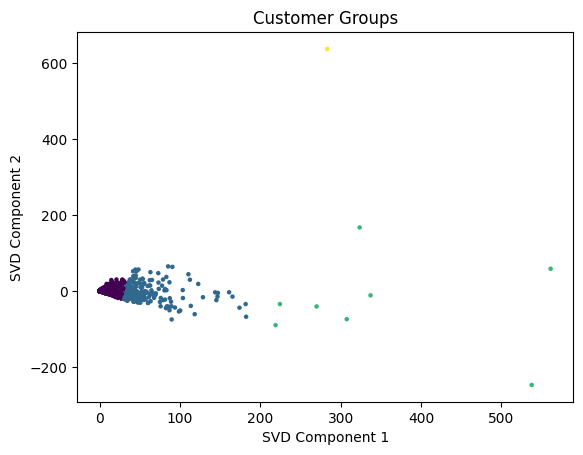

In [77]:
plt.scatter(customers_2d[:, 0], customers_2d[:, 1], c=groups, s=5)
plt.xlabel('SVD Component 1')
plt.ylabel('SVD Component 2')
plt.title('Customer Groups')
plt.show()

As we can see, there are some customers that are considered extreme outliers, whom are distorting the means clustering, we can modify the clustering to account for these customers

In [78]:
customers_scaled = np.sign(customers_2d) * np.log1p(abs(customers_2d))
kmeans = KMeans(n_clusters=4, random_state=2, n_init=10)
groups = kmeans.fit_predict(customers_scaled)
np.unique(groups, return_counts=True)

(array([0, 1, 2, 3], dtype=int32), array([2956,  459,  961, 1097]))

We now have 4 groups which are more balanced, using a logarithmic scale, this allows for the extreme values to be reduced

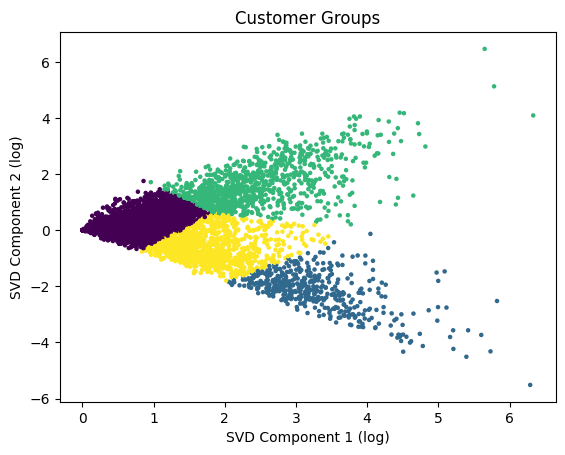

In [80]:
plt.scatter(customers_scaled[:, 0], customers_scaled[:, 1], c=groups, s=5)
plt.xlabel('SVD Component 1 (log)')
plt.ylabel('SVD Component 2 (log)')
plt.title('Customer Groups')
plt.show()

While we can see the different groups through their transformed (log scaled) SVD, we still don't undertand the differences between these groups

ML6: Identifying Each Groups Top Products

In [81]:
customer_groups = pd.DataFrame({
    'Customer ID': list(cust.keys()),
    'Group': groups})
group_data = train.merge(customer_groups, on='Customer ID')
group_data.groupby(['Group', 'Description'])['Quantity'].sum().groupby(level=0, group_keys=False).nlargest(5)

Group  Description                        
0      MEDIUM CERAMIC TOP STORAGE JAR         74462
       BLACK AND WHITE PAISLEY FLOWER MUG     25188
       SMALL CHINESE STYLE SCISSOR            25146
       SET/6 WOODLAND PAPER PLATES            12965
       SET/6 STRAWBERRY PAPER CUPS            12962
1      JUMBO BAG RED RETROSPOT                54496
       WORLD WAR 2 GLIDERS ASSTD DESIGNS      48147
       BROCADE RING PURSE                     46004
       60 TEATIME FAIRY CAKE CASES            31612
       JUMBO BAG STRAWBERRY                   29305
2      WHITE HANGING HEART T-LIGHT HOLDER     64181
       ASSORTED COLOUR BIRD ORNAMENT          38601
       VICTORIAN GLASS HANGING T-LIGHT        25768
       WORLD WAR 2 GLIDERS ASSTD DESIGNS      18607
       COLOUR GLASS T-LIGHT HOLDER HANGING    18320
3      WORLD WAR 2 GLIDERS ASSTD DESIGNS      22966
       PACK OF 12 SUKI TISSUES                19893
       PACK OF 12 WOODLAND TISSUES            17745
       PACK OF 12 PINK PAISLEY TISSUES        16854
       PACK OF 12 RED SPOTTY TISSUES          15829
Name: Quantity, dtype: int64

While these represent the top products for each group, there are only preliminary interpretations that can be conducted, specially as the total quantity may be influenced by customers making purchases in large quanitites.

We then sort the customer groups by countries

In [82]:
group_data.groupby(['Group', 'Country'])['Customer ID'].nunique().groupby(level=0, group_keys=False).nlargest(5)

Group  Country       
0      United Kingdom    2788
       France              27
       Germany             24
       Spain               17
       Netherlands          8
1      United Kingdom     362
       Germany             29
       France              22
       Belgium             10
       Switzerland          6
2      United Kingdom     930
       Cyprus               4
       Germany              4
       France               3
       Greece               3
3      United Kingdom     915
       Germany             40
       France              33
       Belgium             15
       Spain               13
Name: Customer ID, dtype: int64

We decide to name the segments as follows:
Group 0: Household/Essentials (Primarily UK customers with kitchen items and storing items)
Group 1: Gifts (UK majority with some German and French customers, includes shopping bags, toys, and purses)
Group 2: Home Decoration (Mostly UK customers, includes candle holders, ornaments, and glass)
Group 3: Everyday Goods (Includes tissue packs and novelty items, mainly UK customers with some German and French customers as well)

Comparisson

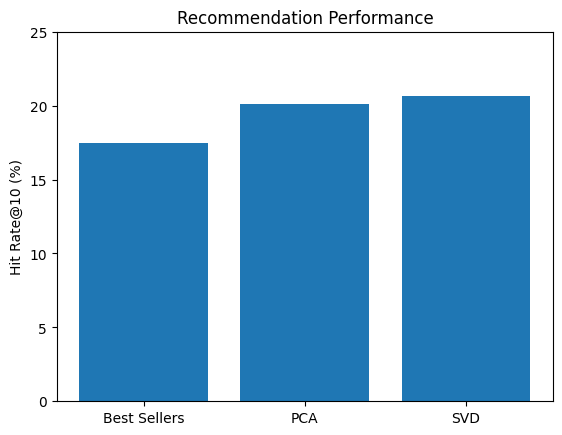

In [83]:
models = ['Best Sellers', 'PCA', 'SVD']
rates = [17.48, 20.14, 20.66]

plt.bar(models, rates)
plt.ylabel('Hit Rate@10 (%)')
plt.title('Recommendation Performance')
plt.ylim(0, 25)
plt.show()